# Fractional PDE solver: demo

Solves the fractional Burgers equation on a periodic domain $x\in[0,L)$:

$$\partial_t^\alpha u + c\,u\,\partial_x u = -\nu\,(-\Delta)^{\beta/2}u$$

with a Caputo time derivative of order $\alpha\in(0,1]$ and a fractional space order $\beta\in(0,2]$. $(-\Delta)^{\beta/2}$ is the Fourier multiplier $|k|^\beta$, so *$\beta$ is the spatial order of the dissipation* and *$\alpha$ is the time order*. With $\alpha=1,\ \beta=2$ it is the classical viscous Burgers equation $u_t + c\,u\,u_x=\nu u_{xx}$.

| type | $\alpha$ | $\beta$ |
|---|---|---|
| space-fractional | $=1$ | $<2$ |
| time-fractional (Caputo) | $<1$ | $=2$ |
| space-time fractional | $<1$ | $<2$ |

**Method.** Fourier pseudo-spectral in $x$ (2/3 dealiasing), Caputo **L1** scheme in $t$ with a uniform step $\tau$. The linear part $\nu|k|^\beta$ is implicit and the nonlinear term $c\,u\,u_x$ explicit (first order). Cost $O(N_t^2)$ because of the memory sum.

**Linear, nonlinear.** The coefficient $c$ controls the nonlinearity. With $c=0$ the problem is *linear*: each Fourier mode evolves independently, $\hat u_k(t)=E_\alpha(-\nu|k|^\beta t^\alpha)\,\hat u_k(0)$ ($E_\alpha$ = Mittag-Leffler function, `exact_linear`). With $c\neq0$ it is *nonlinear*: $u\,u_x$ couples the modes (fronts steepen) and there is no closed form. What is fractional: the time derivative (order $\alpha$, with memory of the whole past) and the dissipation (order $\beta$); the nonlinear term $u\,u_x$ is the usual integer-order one.

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Markdown
from fpde_solver import *

INK, MUTED = '#1f2328', '#6b7280'
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
CMAP = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#d6402a'])
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'text.color': INK, 'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 9})

def plot_fields(fields, titles, T, L, ncols, suptitle=''):
    # x-t heatmaps of u[t, x] on one colour scale
    nrows = -(-len(fields) // ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 2.7 * nrows), sharex=True, sharey=True, squeeze=False)
    ok = [u for u in fields if np.isfinite(u).all()]                  # colour scale from the runs that did not blow up
    lo, hi = min(u.min() for u in ok), max(u.max() for u in ok)
    for ax, u, title in zip(axs.ravel(), fields, titles):
        im = ax.imshow(u, origin='lower', aspect='auto', extent=[0, L, 0, T], cmap=CMAP, vmin=lo, vmax=hi)
        ax.set_title(title, loc='left', fontsize=8, color='#d6402a' if not np.isfinite(u).all() else INK)
    for ax in axs[-1]: ax.set_xlabel('x')
    for ax in axs[:, 0]: ax.set_ylabel('t')
    fig.suptitle(suptitle, x=0.01, ha='left', fontsize=10)
    fig.colorbar(im, ax=axs, label='u', pad=0.01); plt.show()


## 1. Demo: one case per type
Same random initial condition and parameters for the three types (values printed below).

burgers: {'nu': 0.05, 'c': 1.0}, L=6.283, T=1.0, N=128, Nt=800, ic: p=2 seed=3


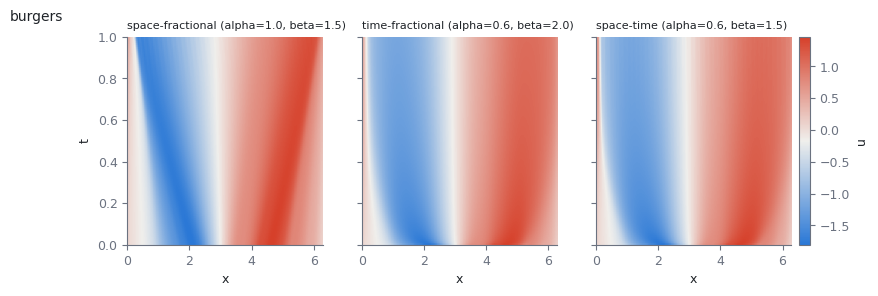

In [ ]:
NU, C, L, T, NT = 0.05, 1.0, 2 * np.pi, 1.0, 800           # viscosity, nonlinearity, domain length, final time, time steps
N, P_IC, SEED, FRAMES = 128, 2, 3, 101                      # grid points; initial condition: spectrum slope p and seed; saved frames per run
CASES = {'space-fractional': (1.0, 1.5), 'time-fractional': (0.6, 2.0), 'space-time': (0.6, 1.5)}      # name: (alpha, beta)
ALPHAS, BETAS = (1.0, 0.8, 0.6), (2.0, 1.5, 1.2)            # (alpha, beta) of the alpha-beta grid

eq = burgers(nu=NU, c=C)
print(f'{eq.name}: {eq.params}, L={L:.4g}, T={T}, N={N}, Nt={NT}, ic: p={P_IC} seed={SEED}')
u0 = eq.ic(1, N, P_IC, SEED)
fields = [solve(u0, a, b, T, NT, eq, L, NT // (FRAMES - 1))[1][0] for a, b in CASES.values()]
plot_fields(fields, [f'{n} (alpha={a}, beta={b})' for n, (a, b) in CASES.items()], T, L, len(CASES), eq.name)


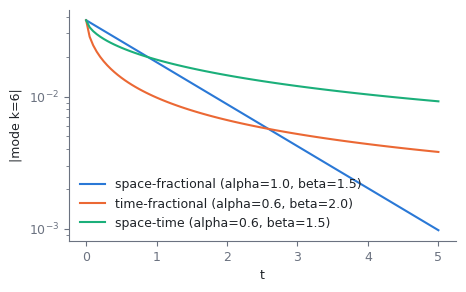

In [ ]:
# Memory: amplitude of one Fourier mode, linear problem (c=0, i.e. fractional diffusion). Exponential decay for alpha=1, slow power-law tail for alpha<1.
K_MODE, T_LONG, NT_LONG = 6, 5.0, 400
lin = burgers(nu=NU, c=0.0)
u0 = lin.ic(1, N, P_IC, SEED)
fig, ax = plt.subplots(figsize=(5, 3))
for (name, (a, b)), col in zip(CASES.items(), (BLUE, ORANGE, AQUA)):
    t, u = solve(u0, a, b, T_LONG, NT_LONG, lin, L, NT_LONG // 100)
    ax.semilogy(t, 2 * np.abs(np.fft.rfft(u[0], axis=-1)[:, K_MODE]) / N, color=col, lw=1.5, label=f'{name} (alpha={a}, beta={b})')
ax.set_xlabel('t'); ax.set_ylabel(f'|mode k={K_MODE}|'); ax.legend(frameon=False); plt.show()


### Different initial conditions
Same equation and fractional orders (`CASE`), different random initial conditions: `p` is the slope of the amplitude spectrum $|k|^{-p}$ (small `p` = rougher), `seed` changes the phases.

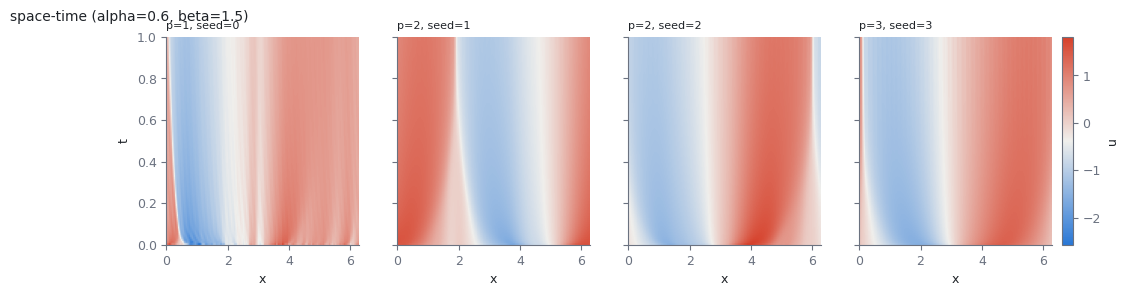

In [ ]:
CASE = 'space-time'                                        # which entry of CASES to use
IC_SPECS = [(1, 0), (2, 1), (2, 2), (3, 3)]                 # (p, seed)
a, b = CASES[CASE]
fields = [solve(eq.ic(1, N, p, s), a, b, T, NT, eq, L, NT // (FRAMES - 1))[1][0] for p, s in IC_SPECS]
plot_fields(fields, [f'p={p}, seed={s}' for p, s in IC_SPECS], T, L, len(IC_SPECS), f'{CASE} (alpha={a}, beta={b})')


### Different values of alpha and beta
Same initial condition; rows: time order $\alpha$, columns: space order $\beta$. A red title marks a run that blew up; see the stability scan in section 2 for the needed `Nt`.

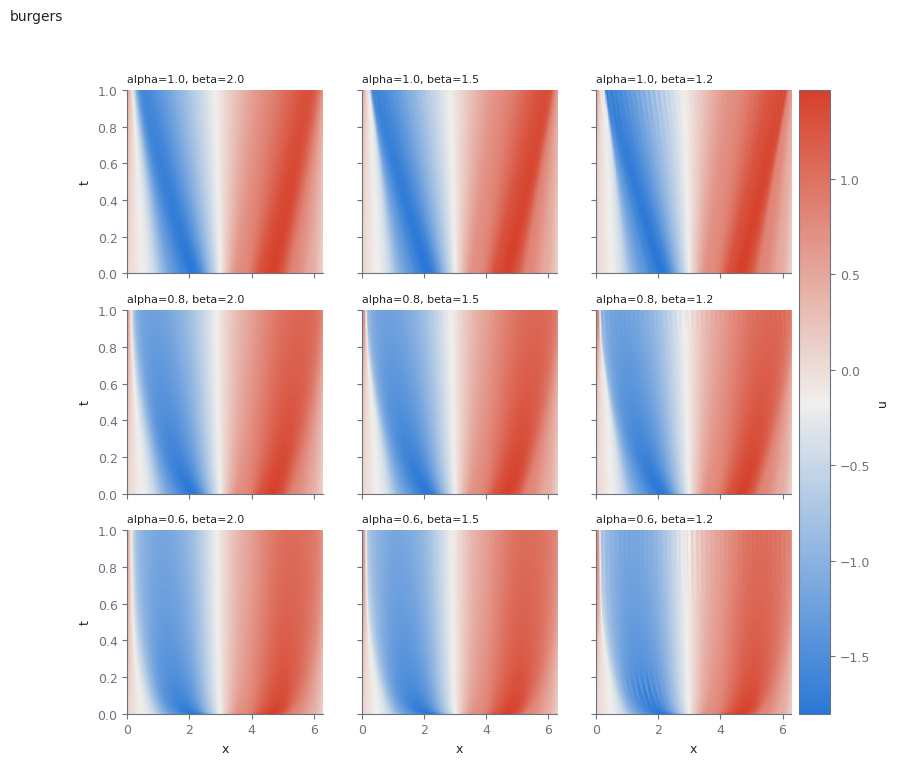

In [ ]:
u0 = eq.ic(1, N, P_IC, SEED)
pairs = [(a, b) for a in ALPHAS for b in BETAS]
fields = [solve(u0, a, b, T, NT, eq, L, NT // (FRAMES - 1))[1][0] for a, b in pairs]
plot_fields(fields, [f'alpha={a}, beta={b}' + ('' if np.isfinite(u).all() else '  (unstable)') for (a, b), u in zip(pairs, fields)], T, L, len(BETAS), eq.name)


## 2. Stability check
`min_stable_steps(eq, alpha, beta, T, ...)` returns the smallest tested `Nt` for which 2 random initial conditions stay finite (finite does not mean accurate). The explicit step is effectively $\tau^\alpha\Gamma(2-\alpha)$, which is large for small $\alpha$, so small $\alpha$ or $\beta$ need more steps; `X` = unstable for every tested `Nt`.

In [6]:
STEPS = (200, 400, 800, 1600, 3200)
SCAN_ALPHAS, SCAN_BETAS = (1.0, 0.8, 0.6, 0.5, 0.4), (2.0, 1.5, 1.2)
stable = lambda a, b: min_stable_steps(eq, a, b, T, STEPS, N, L, P_IC, SEED)
print(f"{eq.name}  (L={L:.4g}, T={T}), smallest stable Nt;  rows alpha, columns beta")
print('alpha \\ beta ' + ''.join(f'{b:>8}' for b in SCAN_BETAS))
for a in SCAN_ALPHAS:
    print(f'{a:<13}  ' + ''.join(f"{(stable(a, b) or 'X'):>8}" for b in SCAN_BETAS))
case_steps = {n: stable(a, b) for n, (a, b) in CASES.items()}       # same test for the demo cases


burgers  (L=6.283, T=1.0), smallest stable Nt;  rows alpha, columns beta
alpha \ beta      2.0     1.5     1.2
1.0                 200     200     200
0.8                 200     200     400
0.6                 200     800     800
0.5                 200    1600    3200
0.4                 200       X       X


## 3. Dataset generator
`make_dataset(eq, alpha, beta, n_samples, N, L, T, Nt, save_every, p, seed, path)` generates the trajectories for one $(\alpha,\beta)$ and many random initial conditions. It raises an error if the run blows up at the given `Nt` (use the check above), and saves a compressed `.npz` (`u` of shape `[n_samples, frames, N]`, `t`, `x`, and the settings) when `path` is given. One file per setting. The full dataset is **not** generated here; the cell below only builds 2 samples to show the interface and the cost.

In [7]:
DATASET = dict(frames=21, n_train=200, n_test=50)             # everything else comes from the variables above; save_every = NT // (frames - 1)
general = [('`eq`', f'`burgers(nu={NU}, c={C})`', 'c=0 makes the problem linear'), ('`N`', f'{N}', f'2/3 dealiasing leaves {N // 3} active modes'), ('`L`, `T`, `Nt`', f'{L:.4g}, {T}, {NT}', 'domain length, final time, time steps; solver step tau = T/Nt'), ('`save_every`', f"Nt // {DATASET['frames'] - 1}", f"{DATASET['frames']} saved frames per run"), ('initial conditions', f'`eq.ic(B, N, p={P_IC}, seed)`', 'random Fourier series, amplitudes ~ k^-p; store `p` and `seed`'), ('samples', f"{DATASET['n_train']} train + {DATASET['n_test']} test per setting", '`B` is batched; `make_dataset` works in chunks of 50'), ('noise', 'added after solving, not in the solver', 'sigma * std of the snapshots at the same time')]
display(Markdown('| argument | value | comment |\n|---|---|---|\n' + '\n'.join('| ' + ' | '.join(r) + ' |' for r in general)))

per_case = [(f'`{n}`', f'({a}, {b})', f"{case_steps[n] or 'X'}", '' if case_steps[n] and case_steps[n] <= NT else f'unstable at Nt={NT}: raise Nt') for n, (a, b) in CASES.items()]
display(Markdown('| type | (alpha, beta) | smallest stable Nt | warning |\n|---|---|---|---|\n' + '\n'.join('| ' + ' | '.join(r) + ' |' for r in per_case)))

for n, (a, b) in CASES.items():
    t0 = time.time()
    ds = make_dataset(eq, a, b, 2, N, L, T, NT, NT // (DATASET['frames'] - 1), P_IC, SEED)
    print(f"{n}: u {ds['u'].shape}, t in [0, {ds['t'][-1]}], {time.time() - t0:.1f}s for 2 samples")


| argument | value | comment |
|---|---|---|
| `eq` | `burgers(nu=0.05, c=1.0)` | c=0 makes the problem linear |
| `N` | 128 | 2/3 dealiasing leaves 42 active modes |
| `L`, `T`, `Nt` | 6.283, 1.0, 800 | domain length, final time, time steps; solver step tau = T/Nt |
| `save_every` | Nt // 20 | 21 saved frames per run |
| initial conditions | `eq.ic(B, N, p=2, seed)` | random Fourier series, amplitudes ~ k^-p; store `p` and `seed` |
| samples | 200 train + 50 test per setting | `B` is batched; `make_dataset` works in chunks of 50 |
| noise | added after solving, not in the solver | sigma * std of the snapshots at the same time |

| type | (alpha, beta) | smallest stable Nt | warning |
|---|---|---|---|
| `space-fractional` | (1.0, 1.5) | 200 |  |
| `time-fractional` | (0.6, 2.0) | 200 |  |
| `space-time` | (0.6, 1.5) | 800 |  |

space-fractional: u (2, 21, 128), t in [0, 1.0], 0.1s for 2 samples
time-fractional: u (2, 21, 128), t in [0, 1.0], 0.1s for 2 samples
space-time: u (2, 21, 128), t in [0, 1.0], 0.1s for 2 samples


Limitations to keep in mind: first order in $\tau$ for the nonlinear term; the symmetric symbol $|k|^\beta$ is not the one-sided derivative used in `tsfade_fft`; the cost grows as $N_t^2$.